In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'

In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [3]:
import sys
from copy import deepcopy
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse, Circle, Arc
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.animation as animation
from PIL import Image, ImageSequence
import seaborn as sns
import cmocean
import colorcet
import cmasher
from IPython.display import HTML

from cogwheel import gw_utils, utils, plotting, gw_plotting
import cogwheel.posterior

sys.path.insert(0, '/home/abbye.williams/GWPE/code')
# from generate_injection_params import generate_injection_parameters
import helpers
from injections import create_injection

### overall params

In [4]:
cII = '#0186DF'    # Type II lensing color
c_imp = "#CE0003"
prussian = '#0D2149' 
plotdir = '../data/plots/midwest_relativity'

### waveform (title slide?)

In [5]:
# injection parameters
seed = 12
approximant = 'IMRPhenomXPHM'

# parameters to inject
pars_to_inject = {
    'm1' : 15., # Msun
    'm2' : 9., # Msun
    'd_luminosity' : 500.,  # Mpc
    'iota' : np.pi / 4.,
    'ra' : 0.5, # fix the sky location for consistency
    'dec' : 0.5,    # rad
    's1z' : 0., # zero spin
    's2z' : 0.,
    's1x' : 0.,
    's1y' : 0.,
    's2x' : 0.,
    's2y' : 0.
}

ed_u = create_injection(pars_to_inject, seed=seed, approximant=approximant, fmax=2048)
# get the full injected parameter dictionary
injected_par_dic = ed_u.injection['par_dic']

# reinstantiate with zero noise
ed_0 = ed_u.reinstantiate(strain=np.zeros_like(ed_u.strain))
# inject the same signal
ed_0.inject_signal(par_dic=injected_par_dic, approximant=approximant)

# Type II lens
ed_0_l = ed_0.reinstantiate(strain=ed_0.strain * 1j)

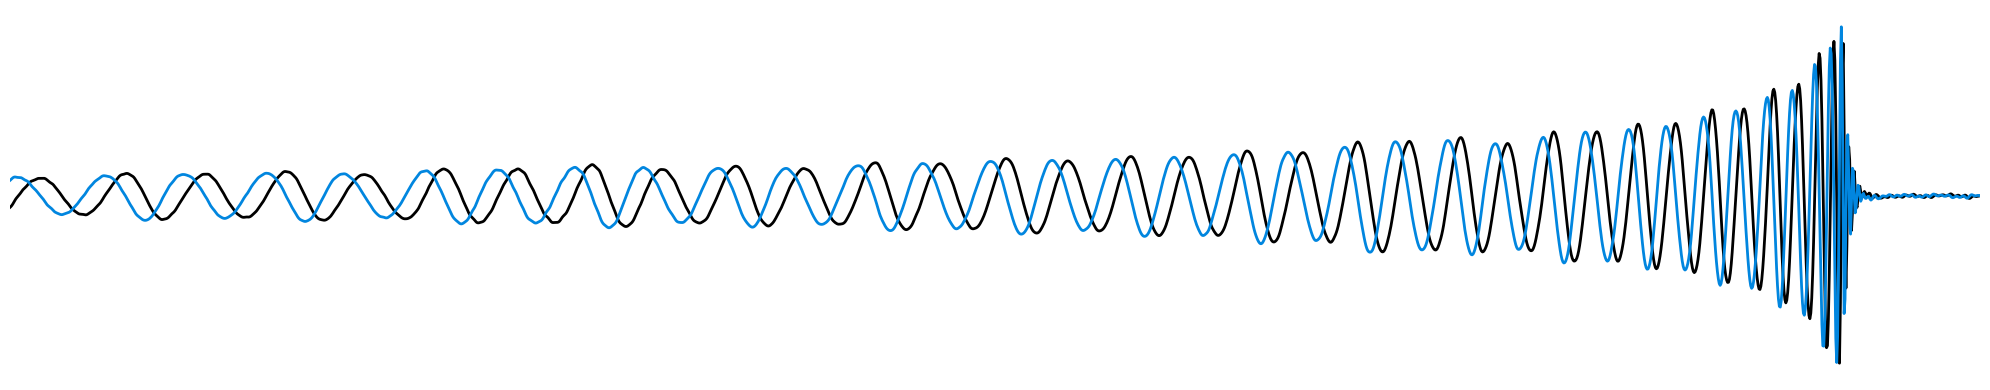

In [7]:
# plot these waveforms
plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(20,4), tight_layout=True)
# fig.text(.0, .54, 'Whitened Strain', rotation=90, ha='left',
#             va='center', fontsize='large')
# ax.text(.02, .95, 'H', ha='left', va='top', transform=ax.transAxes)
ax.tick_params(which='both', direction='in', right=True, top=True, labelsize=12)

plt.xlabel('Time (s)', size=12)

# apply a small time shift to align the relative binning
times = ed_u.times - ed_u.tcoarse
# strain
data_t_wht = ed_0.get_whitened_td(ed_0.strain)
ax.plot(times, data_t_wht[0], c='k', alpha=1., lw=2, ls='-', zorder=0)

# strain
data_t_wht = ed_0_l.get_whitened_td(ed_0_l.strain)
ax.plot(times, data_t_wht[0], c=cII, alpha=1., lw=2, ls='-', zorder=0)

ax.set_xlim(-0.5, 0.02)
ax.set_axis_off()
fig.savefig(os.path.join(plotdir, 'title_waveform.png'))

### time-delay surface

In the geometric optics limit, a lensed image forms wherever the travel time from source to observer is stationary with respect to the image position $\vec\theta$.
Fermat's principle states that the total time delay (or Fermat potential) (up to an overall constant) is
$$
\tau(\vec\theta,\vec\beta) = \frac{1}{2}|\vec\theta-\vec\beta|^2 - \psi(\vec\theta)
$$
with $\beta$ the source position and $\psi$ the lensing potential, which is related to the projected mass distribution of the lens.
For a point mass, the lensing potential is (in units of the Einstein radius $\theta_E = 1$)
$$
\psi(\vec\theta) = \ln|\vec\theta|
$$
If we parametrize the lens plane with $\theta_x$ and $\theta_y$ then we can write
$$
\psi(\vec\theta) = \ln\sqrt{\theta_x^2+\theta_y^2} = \frac{1}{2}\ln(\theta_x^2 + \theta_y^2) \equiv \frac{1}{2}\ln r^2
$$
Now place the source on the x axis such that $\vec\beta=(\beta,0)$.

In [30]:
def fermat(x, y, beta):
    return 0.5 * ((x - beta)**2 + y**2) - 0.5 * np.log(x**2 + y**2)

def arrival_time_surface(x, y, beta, r_hole):
    rsq = x**2 + y**2
    rsq= np.where(rsq < r_hole**2, np.nan, rsq)  # to cut out space around any singularities
    return 0.5 * ((x - beta)**2 + y**2) - 0.5 * np.log(rsq)

In [31]:
xarr = np.linspace(-2 * np.pi / 3, 2 * np.pi / 3, 501)
yarr = np.linspace(-2 * np.pi / 3, 2 * np.pi / 3, 501)
xgrid, ygrid = np.meshgrid(xarr, yarr)

beta = 1.  # the angular position of the source, measured from the optical axis, placed on the x axis
r_hole = 0.02
at_surface = arrival_time_surface(xgrid, ygrid, beta, r_hole)

# find analytically the image positions and their Fermat potential values
disc = np.sqrt(beta**2 + 4.0)   # the Type I and II images lie on this disc in the lens plane
theta_I = (beta + disc) / 2.0
theta_II = (beta - disc) / 2.0
# evaluate tau(theta) = 0 at y = 0 (since images are on the axis)
phi_I = fermat(theta_I, 0, beta)
phi_II = fermat(theta_II, 0, beta)

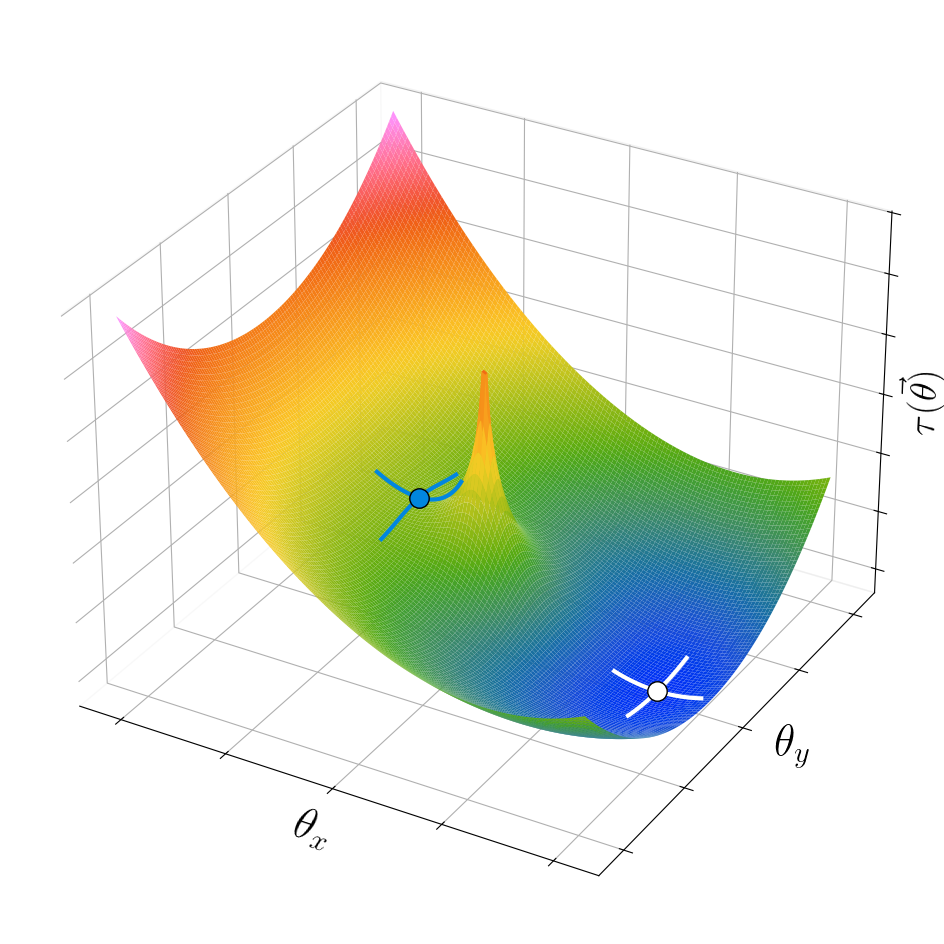

In [32]:
# plotting params
plt.rcParams['font.family'] = 'serif'
cmap = colorcet.cm.CET_R1 #cmasher.get_sub_cmap('cmr.tropical', 0.2, 1.)
# other options: sns.color_palette('turbo', as_cmap=True) sns.cubehelix_palette(start=-1.3, rot=0.75, reverse=True, as_cmap=True)
lift = 0.05   # cosmetic lift so the curves lie slightly above the surface
cI = 'w'
marker_kwargs = dict(marker='o', mec='k', lw=0.5, zorder=100, ms=14)

fig, ax = plt.subplots(figsize=(12,12), subplot_kw={"projection": "3d"})
ax.plot_surface(xgrid, ygrid, at_surface, alpha=1.,
                cmap=cmap, rcount=150, ccount=150)

lw1 = 3
# Type II image location
lx = 0.4       # half length that we want the curve to be
mx = np.linspace(theta_II - lx, theta_II + lx, 101)
ax.plot(mx, np.zeros_like(mx), fermat(mx, 0, beta) + lift, color=cII, alpha=1., lw=lw1, zorder=100)
# the downhill
ly = 0.6
my = np.linspace(-ly, ly, 101)
ax.plot(np.ones_like(my) * theta_II, my, fermat(theta_II, my, beta) + lift, color=cII, alpha=1., lw=lw1, zorder=100)
ax.plot(theta_II, 0, fermat(theta_II, 0, beta) + lift, color=cII, **marker_kwargs)
# ax.text(theta_II-0.5, 0.3, fermat(theta_II, 0, beta) + 3 * lift, s="Type II", c=cII, zorder=200)

# Type I image location
lx = 0.4       # half length that we want the curve to be
mx = np.linspace(theta_I - lx, theta_I + lx, 101)
ax.plot(mx, np.zeros_like(mx), fermat(mx, 0, beta) + lift, color=cI, alpha=1., lw=lw1, zorder=100)
# the downhill
ly = 0.5
my = np.linspace(-ly, ly, 101)
ax.plot(np.ones_like(my) * theta_I, my, fermat(theta_I, my, beta) + lift, color=cI, alpha=1., lw=lw1, zorder=100)
ax.plot(theta_I, 0, fermat(theta_I, 0, beta) + lift, color=cI, **marker_kwargs)

# labels, grid lines etc
ax.set_xlabel(r'$\theta_x$', labelpad=0., fontsize=32)
# ax.set_ylabel(r'$\theta_y$', labelpad=0., fontsize=28)
ax.text(np.pi - 0.18, -.55, 0., r'$\theta_y$', fontsize=32)
ax.set_zlabel(r'$\tau(\vec\theta)$', labelpad=-4, fontsize=28)
_ = ax.set(xticklabels=[],
       yticklabels=[],
       zticklabels=[])

ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

fig.savefig(os.path.join(plotdir, 'time_delay_3D.png'))

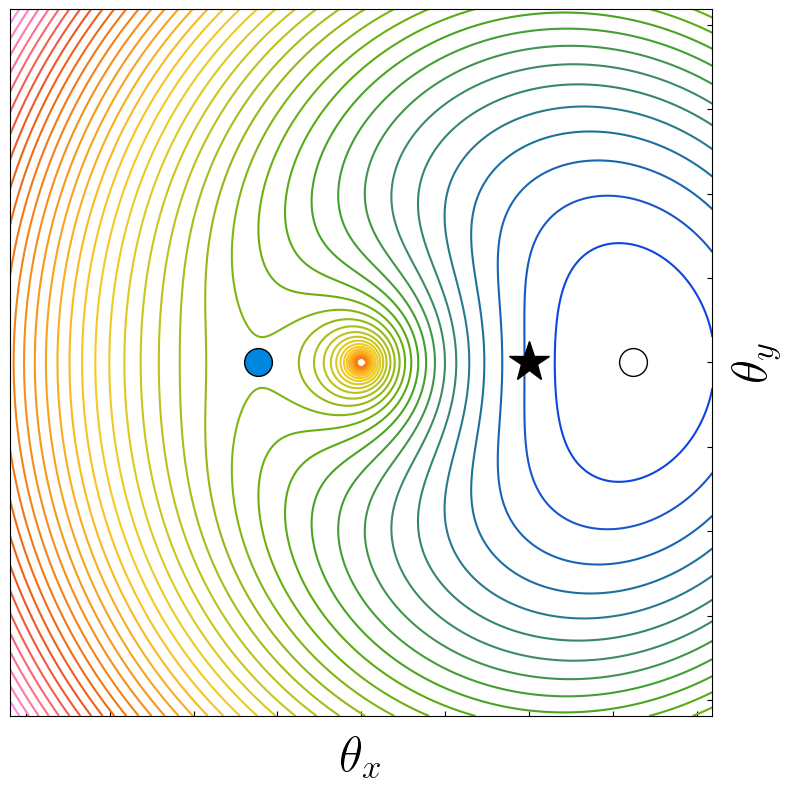

In [15]:
levels = np.linspace(np.nanmin(at_surface), np.nanmax(at_surface), 40)
fig, ax = plt.subplots(figsize=(8,8), tight_layout=True)
norm = mpl.colors.Normalize(vmin=min(levels), vmax=max(levels))
smap = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
colors = [smap.to_rgba(level) for level in levels]
ax.contour(xarr, yarr, at_surface, levels=levels, colors=colors)
ax.plot(beta, 0., marker='*', c='k', mec='k', ms=30)
ax.plot(theta_I, 0., marker='o', c=cI, mec='k', ms=20)
ax.plot(theta_II, 0., marker='o', c=cII, mec='k', ms=20)
_ = ax.set(xticklabels=[], yticklabels=[])
ax.set_xlabel(r'$\theta_x$', fontsize=36, labelpad=10)
ax.yaxis.set_label_position("right")
ax.yaxis.tick_right()
ax.set_ylabel(r'$\theta_y$', fontsize=36, labelpad=10)
ax.tick_params(direction='in')

fig.savefig(os.path.join(plotdir, 'time_delay_contour.png'))

### Type II lensed vs unlensed waveforms

In [8]:
# injection parameters
seed = 12
approximant = 'IMRPhenomXPHM'

# parameters to inject
pars_to_inject = {
    'm1' : 30., # Msun
    'm2' : 10., # Msun
    'd_luminosity' : 500.,  # Mpc
    'iota' : 2 * np.pi / 5.,
    'psi' : 0.,
    'phi_ref' : 0.,
    'ra' : 0.5, # fix the sky location for consistency
    'dec' : 0.5,    # rad
    's1z' : 0., # zero spin
    's2z' : 0.,
    's1x' : 0.,
    's1y' : 0.,
    's2x' : 0.,
    's2y' : 0.
}

In [10]:
# let's make an animation
phi_shifts = np.linspace(0., np.pi / 4, 31)
frames = []
for i, phi_shift in enumerate(phi_shifts):
    ed_u = create_injection(pars_to_inject, seed=seed, approximant=approximant, fmax=2048)
    # get the full injected parameter dictionary
    injected_par_dic = ed_u.injection['par_dic']

    # reinstantiate with zero noise
    ed_0 = ed_u.reinstantiate(strain=np.zeros_like(ed_u.strain))
    # inject the same signal
    ed_0.inject_signal(par_dic=injected_par_dic, approximant=approximant)

    # Type II lens
    ed_0_l = ed_0.reinstantiate(strain=ed_0.strain * 1j)

    # reinstantiate with the unlensed "imposter"
    ed_0_imp = ed_u.reinstantiate(strain=np.zeros_like(ed_u.strain))
    # inject the same signal
    ed_0_imp.inject_signal(par_dic=injected_par_dic | dict(phi_ref=pars_to_inject['phi_ref'] + phi_shift),
                        approximant=approximant)

    frames.append([i, [ed_0, ed_0_l, ed_0_imp]])

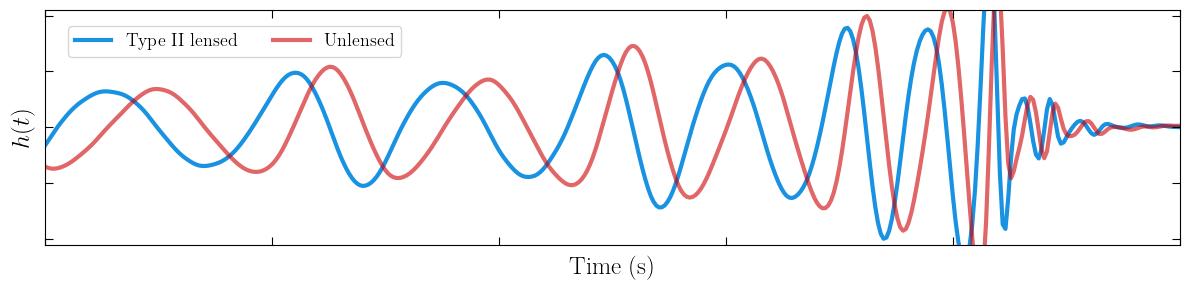

In [11]:
# plot these waveforms
plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(12,3), tight_layout=True)
ax.tick_params(which='both', direction='in', right=True, top=True, length=6)
_ = ax.set(xticklabels=[], yticklabels=[])
ax.set_xlim(-0.1, 0.)
if pars_to_inject['iota'] == 0.:
    ylim = (-1.8, 1.8)
elif pars_to_inject['iota'] == np.pi / 3.:
    ylim = (-1.3, 1.3)
else:
    ylim = (-1.05, 1.05)
ax.set_ylim(ylim) # (-1.8, 1.8)
ax.set_xlabel('Time (s)', size=18)
ax.set_ylabel(r'$h(t)$', size=18)

# create the three lines once, with empty data
styles = zip(['k', cII, c_imp], ['-', '-', '-'], [2, 3, 3], [0.4, 0.9, 0.6])
lines = [ax.plot([], [], c=c, ls=ls, lw=lw, alpha=alpha, zorder=0)[0]
         for c, ls, lw, alpha in styles]
if pars_to_inject['iota'] == 0.:
    labelyloc = -1.65
elif pars_to_inject['iota'] == np.pi / 3.:
    labelyloc = -1.15
else:
    labelyloc = -.95
    
label = ax.text(-0.098, labelyloc, '', fontsize=20, c=c_imp) #-1.65

handles = [
    Line2D([0],[0], color=cII, lw=3, alpha=0.9, label='Type II lensed'),
    Line2D([0],[0], color=c_imp, lw=3, alpha=0.6, label='Unlensed')
]
ax.legend(loc=(0.02, 0.8), ncol=2, handles=handles, fontsize=13)

def update(frame):
    for i, (line, ed) in enumerate(zip(lines, frame[1])):
        if frame[0] == 0 and i == 0:
            continue
        times = ed.times - ed.tcoarse
        data_t_wht = ed.get_whitened_td(ed.strain)
        line.set_data(times, data_t_wht[0])

    ed_0_imp = frame[1][2]
    psi = ed_0_imp.injection['par_dic']['psi']
    if frame[0] == 0:
        label.set_text('')
    else:
        label.set_text(r'$\psi\rightarrow\psi +$' f'{psi / np.pi:.2f}'r'$\pi$')

    return [*lines, label]

ani = animation.FuncAnimation(fig, update, frames=frames, blit=True)

In [12]:
HTML(ani.to_jshtml())

In [16]:
# save if we're happy with it
fn = os.path.join(plotdir, f"waveforms_iota-{pars_to_inject['iota'] / np.pi:.2f}pi.gif")
ani.save(fn, writer='pillow', fps=10, dpi=150)    # this save with pillow will auto-loop the frames forever.

In [17]:
# we can try using ImageSequence to post-process
with Image.open(fn) as im:
    frames = [f.copy() for f in ImageSequence.Iterator(im)]
# append more of the first and last frames
final_frames = [frames[0]] * int(len(frames) * 0.1) + frames + [frames[-1]] * int(len(frames))
final_frames[0].save(fn, save_all=True, append_images=final_frames[1:], duration=100)  # 100 ms = 10 fps

In [ ]:
# # if we want to save as mp4
# import imageio_ffmpeg
# mpl.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
# fnmp4 = os.path.join(plotdir, f"waveforms_iota-{pars_to_inject['iota'] / np.pi:.2f}pi.mp4")
# ani.save(fnmp4, writer="ffmpeg", fps=10, dpi=150,
#          extra_args=["-vcodec", "libx264", "-pix_fmt", "yuv420p"])

### inclination diagram

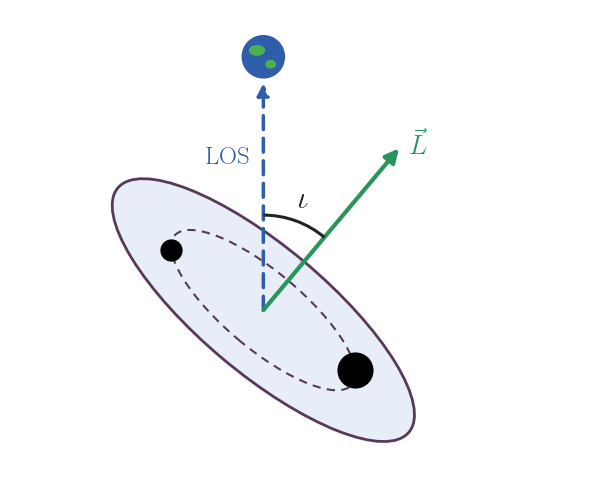

In [19]:
"""
Simple diagram of binary black hole inclination for talks.

Left panel : orbital plane, orbital angular momentum L, line of sight (LOS), iota.
Right panels: what the orbit looks like from Earth at several inclinations.

Convention (gravitational-wave): iota is the angle between L and the line of
sight, so iota = 0 is face-on and iota = 90 deg is edge-on.

Usage:  python bbh_inclination.py
Output: bbh_inclination.png, bbh_inclination.svg
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Circle, Arc

# ----------------------------------------------------------------------------
# Parameters
# ----------------------------------------------------------------------------
IOTA_DEG = 40.0                      # inclination in the left (geometry) panel

PLANE_A, PLANE_B = 1.8, 0.6          # semi-axes of the drawn orbital plane
ORBIT_SCALE = 0.61                   # dashed orbit radius / plane radius
BH_ANGLES_DEG = (20.0, 200.0)        # position of each BH along the orbit
BH_SIZES = (25, 15)                  # marker sizes (points), unequal masses

LOS_LEN, L_LEN = 2.15, 2.0           # arrow lengths (left panel)
ARC_R = 0.9                          # radius of the iota arc

COL_LOS = "#2E5EAA"
COL_L = "#28965A"
COL_PLANE_FILL = "#e8eef7"
COL_PLANE_EDGE = "#593959"
COL_TEXT = "#222222"


def rot(x, y, theta):
    """Rotate (x, y) counter-clockwise by theta (radians)."""
    c, s = np.cos(theta), np.sin(theta)
    return x * c - y * s, x * s + y * c


# ----------------------------------------------------------------------------
# Figure and axes
# ----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6,6), tight_layout=True)

# ----------------------------------------------------------------------------
# Left panel: geometry
# ----------------------------------------------------------------------------
iota = np.radians(IOTA_DEG)
ax.set_aspect("equal")
ax.axis("off")
ax.set_xlim(-2.4, 3)
ax.set_ylim(-1.6, 2.85)

# Unit vectors: line of sight points "up"; L is tilted clockwise by iota
los = np.array([0.0, 1.0])
L = np.array([np.sin(iota), np.cos(iota)])

# Orbital plane: ellipse whose minor axis lies along L (i.e. normal = L)
ax.add_patch(Ellipse((0, 0), 2 * PLANE_A, 2 * PLANE_B, angle=-IOTA_DEG,
                     facecolor=COL_PLANE_FILL, edgecolor=COL_PLANE_EDGE,
                     lw=2, zorder=1))
ax.add_patch(Ellipse((0, 0), 2 * PLANE_A * ORBIT_SCALE,
                     2 * PLANE_B * ORBIT_SCALE, angle=-IOTA_DEG,
                     facecolor="none", edgecolor=COL_PLANE_EDGE, lw=1.5,
                     ls=(0, (4, 3)), zorder=2))

# Line of sight (dashed arrow toward Earth)
ax.annotate("", xy=los * LOS_LEN, xytext=(0, 0), zorder=3,
            arrowprops=dict(arrowstyle="-|>", color=COL_LOS, lw=2.5,
                            ls=(0, (4, 2.5)), mutation_scale=18,
                            shrinkA=0, shrinkB=0))
ax.text(-0.12, 1.45, "LOS", color=COL_LOS, fontsize=18, fontweight="bold",
        ha="right", va="center")

# Orbital angular momentum L
ax.annotate("", xy=L * L_LEN, xytext=(0, 0), zorder=3,
            arrowprops=dict(arrowstyle="-|>", color=COL_L, lw=3,
                            mutation_scale=20, shrinkA=0, shrinkB=0))
tip = L * L_LEN
ax.text(tip[0] + 0.1, tip[1] + 0.03, r"$\vec L$", color=COL_L, fontsize=20,
        fontweight="bold", ha="left", va="center")

# Inclination arc + label (arc runs from L to the line of sight)
ax.add_patch(Arc((0, 0), 2 * ARC_R, 2 * ARC_R, theta1=90 - IOTA_DEG,
                 theta2=90, color=COL_TEXT, lw=2.2, zorder=4))
mid = np.radians(90 - IOTA_DEG / 2)
r_lab = ARC_R + 0.22
ax.text(r_lab * np.cos(mid), r_lab * np.sin(mid), r"$\iota$",
        fontsize=24, color=COL_TEXT, ha="center", va="center", zorder=4)

# Black holes on the orbit, in the plane's rotated frame
for t_deg, size in zip(BH_ANGLES_DEG, BH_SIZES):
    t = np.radians(t_deg)
    x = PLANE_A * ORBIT_SCALE * np.cos(t)
    y = PLANE_B * ORBIT_SCALE * np.sin(t)
    xr, yr = rot(x, y, -iota)
    ax.plot(xr, yr, "o", color="black", ms=size, zorder=5)

# Earth (icon only)
ec = los * (LOS_LEN + 0.25)
ax.add_patch(Circle(ec, 0.2, color=COL_LOS, zorder=6))
for dx, dy, w, h in [(-0.06, 0.06, 0.14, 0.09), (0.07, -0.07, 0.09, 0.07)]:
    ax.add_patch(Ellipse((ec[0] + dx, ec[1] + dy), w, h,
                            color="#4caf50", zorder=7))
fig.savefig(os.path.join(plotdir, 'inclination_diagram1.png'), dpi=200)

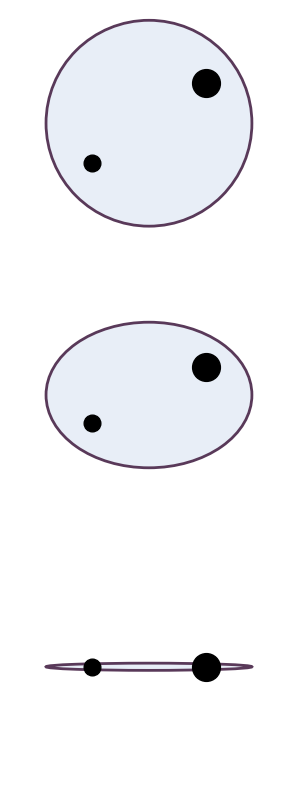

In [20]:
# ----------------------------------------------------------------------------
# Right panels: projected orbit as seen from Earth (circle squashed by cos iota)
# ----------------------------------------------------------------------------
PANEL_IOTAS = [0.0, 45.0, 90.0]      # inclinations in the right-hand panels
PANEL_PHASE_DEG = 35.0               # orbital phase shown in right panels

fig, axs = plt.subplots(3, 1, figsize=(4,10))
R = 1.0
for i, (ax, iv) in enumerate(zip(axs, PANEL_IOTAS)):
    sq = np.cos(np.radians(iv))
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_xlim(-1.35, 1.35)
    ax.set_ylim(-1.1, 1.1)

    # Edge-on would be a zero-height ellipse; keep a sliver so it is visible
    ax.add_patch(Ellipse((0, 0), 2 * R, max(2 * R * sq, 0.07),
                            facecolor=COL_PLANE_FILL,
                            edgecolor=COL_PLANE_EDGE, lw=2))

    phi0 = np.radians(PANEL_PHASE_DEG)
    r_orb = 0.68 * R
    for k, size in enumerate(BH_SIZES):
        phi = phi0 + k * np.pi
        ax.plot(r_orb * np.cos(phi), r_orb * np.sin(phi) * sq, "o",
                    color="black", ms=size * 0.8, zorder=5)

    # ax.text(1.2, 0, rf"$\iota$ = {iv:.0f}°", fontsize=30,
    #             fontweight="bold", color=COL_TEXT, ha="left", va="center")
fig.savefig(os.path.join(plotdir, 'inclination_diagram2.png'), dpi=200)

### Halton results

In [12]:
# load the relevant data

approximant = 'IMRPhenomXPHM'
# get the SNR and compute the Bayes factor
resdir = f'/home/abbye.williams/GWPE/data/injections/Halton/{approximant}/IntrinsicLVCPrior'
seed = 12
nevents = 100

idx_existing = []
# things to save: keys will be the event idx
lnBayes = {}
mismatches = {}
mismatches_nonoise = {}
rhosqs = {}
params = {}

# parameters if we want to compute
# include the noise?
noise = True
n_resamples = 1000

for idx in range(nevents):
    # load the sampler for this event
    eventname = f'GW{seed}_{idx}'
    eventdir = os.path.join(resdir, eventname)
    try:
        event_data, samples, samples_dir = helpers.load_event_data_and_posterior_samples(eventdir, eventname)
        idx_existing.append(idx)
    except FileNotFoundError:
        print(f"no samples for idx {idx}. continuing")
        continue

    # 1. ln Bayes
    lnBayes_fn = os.path.join(samples_dir, 'lnBayes.npy')
    try:
        lnBayes[idx] = np.load(lnBayes_fn)
        if np.isnan(lnBayes[idx][0]):
            lnBayes[idx] = np.array([30., 0.])
    except FileNotFoundError:
        assert False, f"{fn} not found"

    # 2. mismatch (maxlnlike_diff)
    mismatch_dic = np.load(os.path.join(eventdir, 'mismatch.npy'), allow_pickle=True).item()
    mismatches[idx] = mismatch_dic['mismatch']
    rhosqs[idx] = mismatch_dic['rhosq']
    # same thing but without noise
    mismatches_nonoise[idx] = np.load(os.path.join(eventdir, 'mismatch_nonoise.npy'), allow_pickle=True).item()['mismatch']

    # 3. median iota and q from the posterior
    injected_par_dic = event_data.injection['par_dic']
    helpers.add_derived_quantities_injection(injected_par_dic)
    for par_id, injected_value in injected_par_dic.items():
        median_post = utils.quantile(samples[par_id], 0.5, weights=samples['weights'])
        try:
            params[par_id][idx] = (injected_value, median_post)
        except KeyError:    # if the dictionary doesn't exist yet
            params[par_id] = {}
            params[par_id][idx] = (injected_value, median_post)

loaded posterior samples for GW12_0 run 0
loaded posterior samples for GW12_1 run 0
loaded posterior samples for GW12_2 run 0
loaded posterior samples for GW12_3 run 0
loaded posterior samples for GW12_4 run 0
loaded posterior samples for GW12_5 run 0
loaded posterior samples for GW12_6 run 0
loaded posterior samples for GW12_7 run 0
loaded posterior samples for GW12_8 run 0
loaded posterior samples for GW12_9 run 0
loaded posterior samples for GW12_10 run 0
loaded posterior samples for GW12_11 run 0
loaded posterior samples for GW12_12 run 0
loaded posterior samples for GW12_13 run 0
loaded posterior samples for GW12_14 run 0
loaded posterior samples for GW12_15 run 0
loaded posterior samples for GW12_16 run 0
no samples for idx 17. continuing
loaded posterior samples for GW12_18 run 0
loaded posterior samples for GW12_19 run 0
loaded posterior samples for GW12_20 run 0
loaded posterior samples for GW12_21 run 0
loaded posterior samples for GW12_22 run 0
loaded posterior samples for G

In [13]:
# wrap the iotas
medians, injected = np.array(list(params['iota'].values())).T
rec_iotas_wrapped = np.array([
    np.min([iota, np.pi - iota]) for iota in medians.flatten()
])
inj_iotas_wrapped = np.array([
    np.min([iota, np.pi - iota]) for iota in injected.flatten()
])

In [14]:
lnBayes_grid, lnBayes_std_grid = np.array([
    lnBayes[idx] for idx in lnBayes.keys()
]).T
lnBayes_div_rhosq_grid, lnBayes_div_rhosq_std_grid = np.array([
    lnBayes[idx] / rhosqs[idx] for idx in lnBayes.keys()
]).T

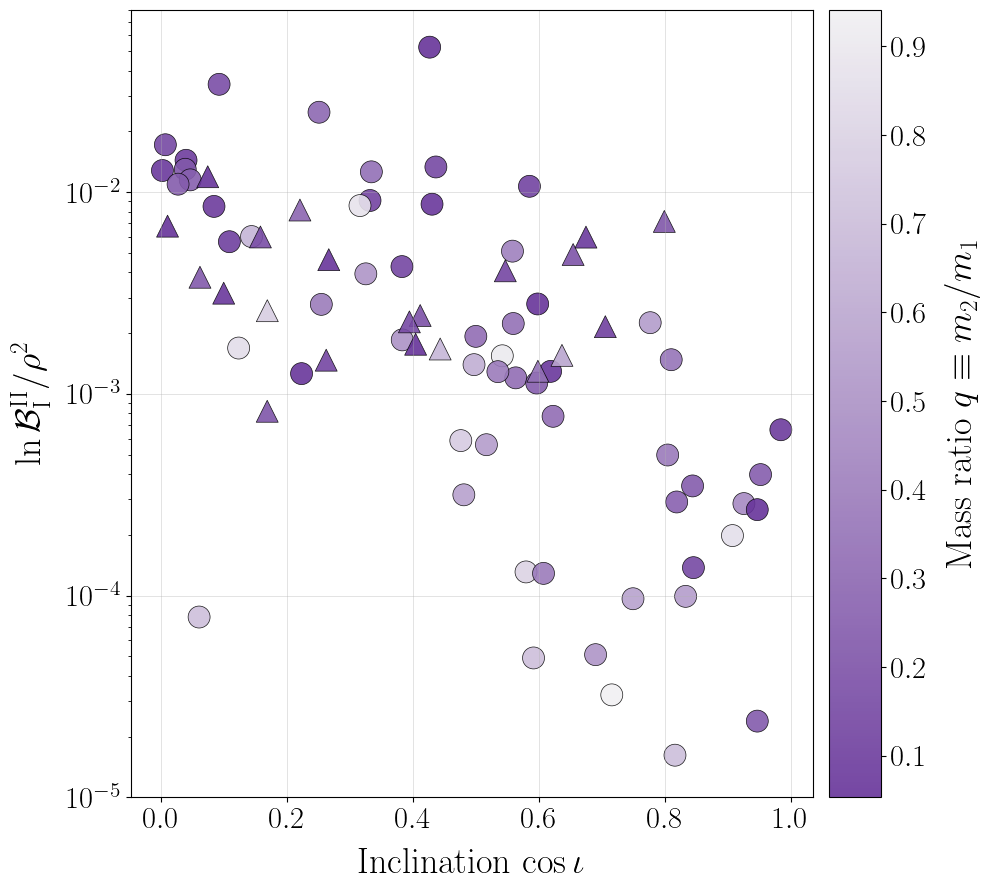

In [15]:
# plot this curve
fig, ax = plt.subplots(figsize=(10,9), tight_layout=True)
plt.rcParams['font.family'] = 'serif'

# different marker for the injections with cutoff to lnB = 30
idx_max = (lnBayes_grid == 30.)
labelsize = 26
ticklabelsize = 22
# xticks = np.arange(0., 0.51, 0.1) * np.pi
# xticklabels = [f'{x / np.pi:.1f}'+r'$\pi$' for x in xticks]
medians_q, injected_q = np.array(list(params['q'].values())).T
cmap = sns.color_palette('light:rebeccapurple_r', as_cmap=True)
norm = mpl.colors.Normalize(vmin=injected_q.min(), vmax=injected_q.max())
kwargs = dict(ec='k', cmap=cmap, norm=norm, alpha=0.9, s=250, lw=0.5)
im = ax.scatter(np.cos(inj_iotas_wrapped)[~idx_max], lnBayes_div_rhosq_grid[~idx_max], marker='o', c=injected_q[~idx_max], **kwargs)
im = ax.scatter(np.cos(inj_iotas_wrapped)[idx_max], lnBayes_div_rhosq_grid[idx_max], marker='^', c=injected_q[idx_max], **kwargs)
cbar = fig.colorbar(im, ax=ax, pad=0.02, aspect=15)
cbar.set_label('Mass ratio 'r'$q\equiv m_2/m_1$', size=labelsize, labelpad=12)
cbar.ax.tick_params(labelsize=ticklabelsize)

# ax.set_xticks(xticks)
# ax.set_xticklabels([])
ax.axhline(0., c='k', alpha=0.5, lw=0.5)
ax.set_ylim(1e-5, 8e-2)
ax.grid(alpha=0.5, lw=0.5)
ax.semilogy()
ax.set_ylabel(r'$\ln\mathcal{B}^\mathrm{II}_\mathrm{I} / \rho^2$', fontsize=labelsize, labelpad=12)
ax.set_xlabel('Inclination 'r'$\cos\iota$', fontsize=labelsize, labelpad=10)
ax.tick_params(labelsize=ticklabelsize)
fig.savefig(os.path.join(plotdir, 'Halton_mismatches_iota.png'), dpi=300)

### example corner plot

In [6]:
lnBayes

{0: array([30.,  0.]),
 1: array([30.,  0.]),
 2: array([30.,  0.]),
 3: array([7.44614607, 0.07727067]),
 4: array([0.05080617, 0.00271291]),
 5: array([9.40039324, 0.05661655]),
 6: array([2.79863135, 0.0158569 ]),
 7: array([0.58641623, 0.00821877]),
 8: array([0.14963471, 0.00472153]),
 9: array([0.75808349, 0.01241036]),
 10: array([-0.03419749,  0.00289893]),
 11: array([23.34647251,  0.26243492]),
 12: array([0.29708095, 0.00748006]),
 13: array([14.12654794,  0.30231689]),
 14: array([-2.62838623,  0.0317885 ]),
 15: array([0.05140924, 0.00294235]),
 16: array([12.0798294,  0.0993409]),
 18: array([0.07413497, 0.00540371]),
 19: array([30.,  0.]),
 20: array([30.,  0.]),
 21: array([6.78794299, 0.0218542 ]),
 22: array([30.,  0.]),
 23: array([30.,  0.]),
 24: array([-0.0646687 ,  0.00920294]),
 25: array([-0.05350393,  0.00156014]),
 27: array([3.81134659, 0.03540253]),
 28: array([8.0711655 , 0.10029545]),
 29: array([0.33735947, 0.01670743]),
 30: array([1.17718745, 0.012905

In [7]:
# load the samples for this event
idx = 6
eventname = f'GW{seed}_{idx}'
eventdir = os.path.join(resdir, eventname)
event_data, samples, samples_dir = helpers.load_event_data_and_posterior_samples(eventdir, eventname)
lnBayes[idx]

loaded posterior samples for GW12_6 run 0


array([2.79863135, 0.0158569 ])

In [8]:
# shift psi over by pi/2 and wrap
psi = samples['psi']
psi_shifted = np.mod(psi + np.pi / 2, np.pi)
samples['psi'] = psi_shifted
# same with injected value
inj_par_dic = event_data.injection['par_dic']
inj_par_dic['psi'] = np.mod(inj_par_dic['psi'] + np.pi / 2, np.pi)

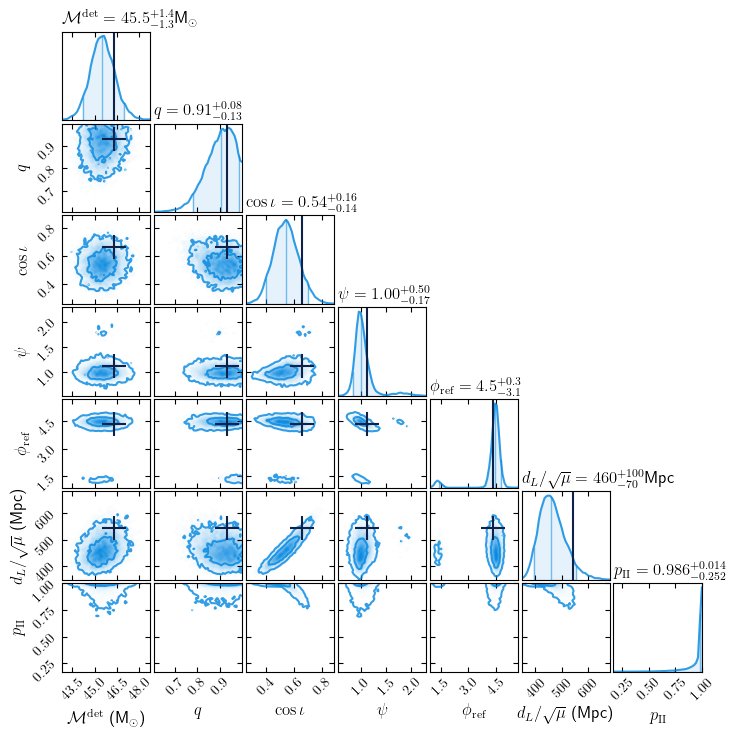

In [9]:
c_l = cII
c_inj = prussian
corner_plot_kwargs = dict(tail_probability=1e-3, color_2d=c_l,
    kwargs_1d=dict(color=c_l, alpha=0.8), contour_kwargs=dict(alpha=0.8))
samples['cosiota'] = np.cos(samples['iota'])
pars_to_plot = [
    'mchirp', 'q', 'cosiota', 'psi', 'phi_ref', 'd_luminosity_lensed', 'p_lensed'
]
cp = gw_plotting.CornerPlot(samples, params=pars_to_plot, **corner_plot_kwargs)
cp.plot(max_figsize=8)
# injected parameters
inj_par_dic = event_data.get_init_dict()['injection']['par_dic']
helpers.add_derived_quantities_injection(inj_par_dic)
inj_par_dic['cosiota'] = np.cos(inj_par_dic['iota'])
inj_pars_to_plot = {k : v for k, v in inj_par_dic.items() if k in pars_to_plot}
cp.scatter_points(inj_pars_to_plot, colors=[c_inj], s=300,   # '#FF2020'
                                    zorder=2, marker='+', adjust_lims=True)
for ax in cp.axes.ravel():
    ax.xaxis.label.set_size(12)
    ax.yaxis.label.set_size(12)
# cp.fig.savefig('/home/abbye.williams/GWPE/data/plots/paper/Halton_corner_plot.pdf')

In [10]:
# get the titles
titles = [
    ax.get_title('left') for ax in cp.axes.ravel()
]

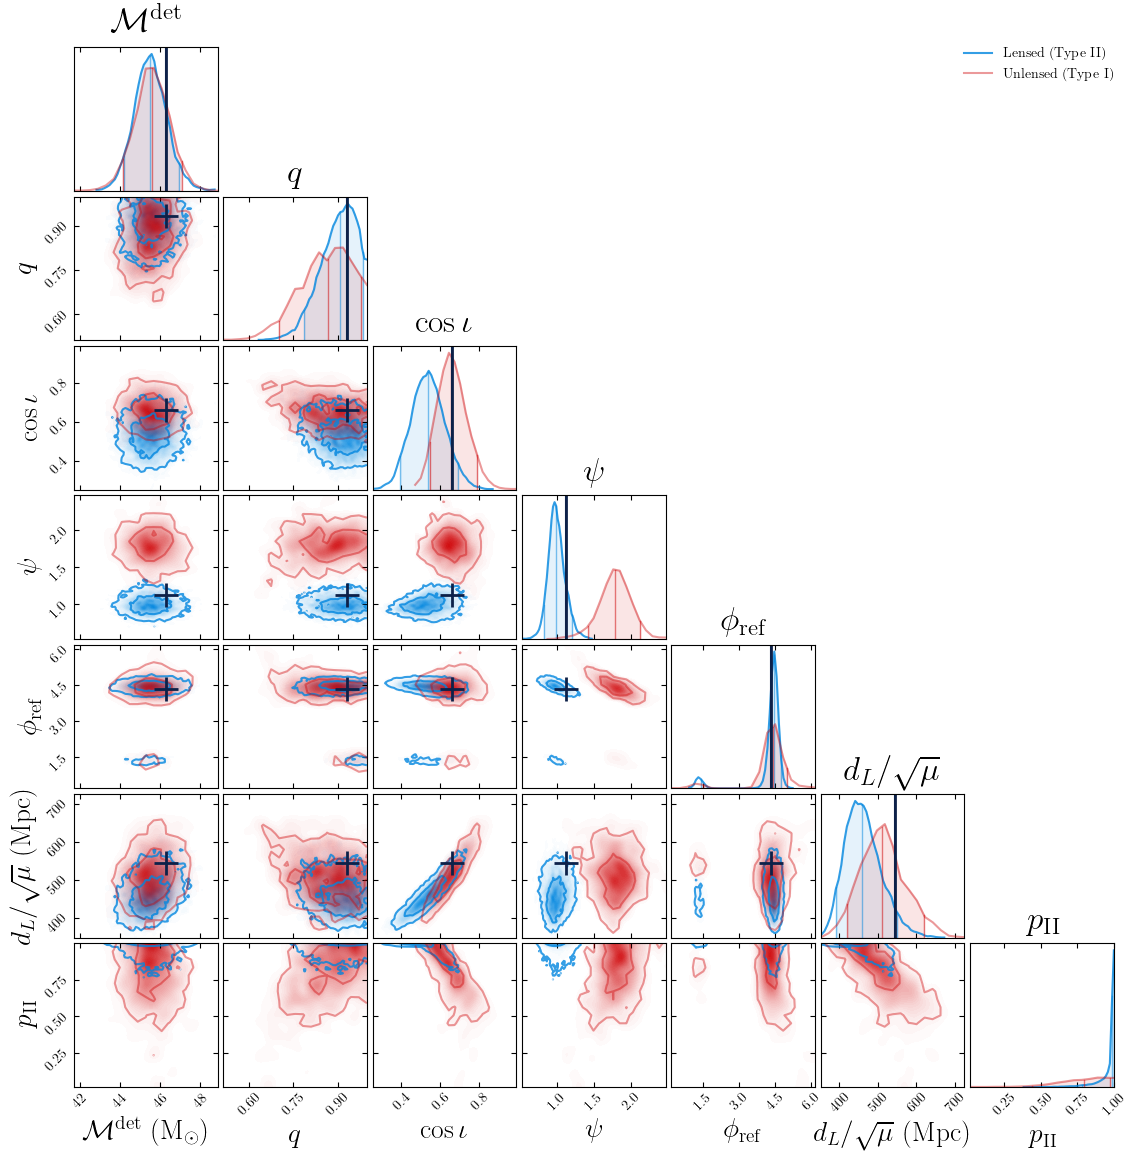

In [11]:
# split lensed and unlensed
plt.rcParams['font.family'] = 'serif'
c1, c2 = c_l, c_imp
plotstyles = [
    plotting.PlotStyle(color_2d=c1, contour_kwargs=dict(alpha=0.8), kwargs_1d=dict(color=c1, alpha=0.8), tail_probability=1e-3),
    plotting.PlotStyle(color_2d=c2, contour_kwargs=dict(alpha=0.4), kwargs_1d=dict(color=c2, alpha=0.4), tail_probability=1e-3)
]
lensed_idx = samples['lensed']
cp = gw_plotting.MultiCornerPlot({'Lensed (Type II)' : samples[lensed_idx], 'Unlensed (Type I)' : samples[~lensed_idx]},
                                    params=pars_to_plot, plotstyles=plotstyles, density=False)
cp.plot(max_figsize=12)
cp0 = cp.corner_plots[0]

# injected parameters
inj_pars_to_plot = {k : v for k, v in inj_par_dic.items() if k in pars_to_plot}
cp.scatter_points(inj_pars_to_plot, colors=[c_inj], s=300, lw=2,
                                    zorder=2, marker='+', adjust_lims=True)
for ax, par in zip(np.diagonal(cp0.axes), cp0.params):
    ax.set_title(gw_plotting._LABELS[par], loc='center', fontsize=24, y=1.04)
    if par != 'p_lensed':
        ax.axvline(inj_pars_to_plot[par], color=c_inj, lw=2)
for i, ax in enumerate(cp0.axes.ravel()):
    ax.set_title('', loc='left', fontsize=16)
    ax.xaxis.label.set_size(20)
    ax.yaxis.label.set_size(20)
cp0.fig.savefig(os.path.join(plotdir, f'{eventname}_corner_split.png'), dpi=300)

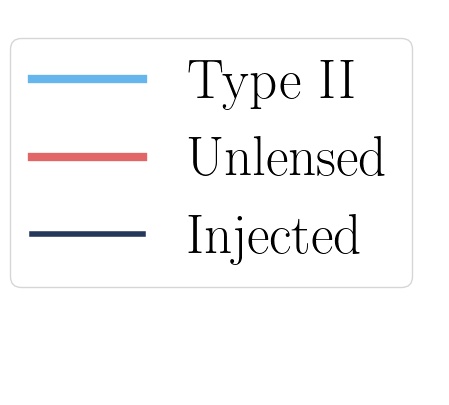

In [52]:
# custom legend
fig, ax = plt.subplots(figsize=(5,5))
handles = [
    Line2D([0], [0], c=cII, lw=6, alpha=0.6, label='Type II'),
    Line2D([0], [0], c=c_imp, lw=6, alpha=0.6, label='Unlensed'),
    Line2D([0], [0], c=c_inj, lw=4, alpha=0.9, label='Injected')
]
ax.legend(handles=handles, fontsize=40)
_ = ax.axis('off')
fig.savefig(os.path.join(plotdir, f'{eventname}_corner_split_legend.png'), dpi=300)